In [ ]:
from mpmath import \
    linspace !wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-18 15:00:47--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  1.27MB/s    in 0.2s    

2026-10-18 15:00:47 (1.27 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [26]:
import pandas as pd

In [48]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [28]:
print(df.head())

      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  


In [17]:
print(len(df))

5000


In [29]:
print(df.isnull().sum())

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [19]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [49]:
# Select categorical columns (object and category dtypes)
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Select all numeric columns and drop the target variable 'converted'
numerical_columns = (
    df.select_dtypes(include='number')
    .columns
    .drop('converted', errors='ignore')
    .tolist()
)

/var/folders/gg/whpf76fd5ysd8_7q0_zzr1l80000gn/T/ipykernel_30003/44977251.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [50]:
df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0)
print(df.isna().sum())
print(df.head())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64
      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student             NA   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.

In [51]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [52]:
from sklearn.metrics import roc_auc_score

auc_scores = {}

for col in numerical_columns:
    auc = roc_auc_score(df_train['converted'], df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[col])

    auc_scores[col] = auc
    print(f'{col}: {auc:.4f}')

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


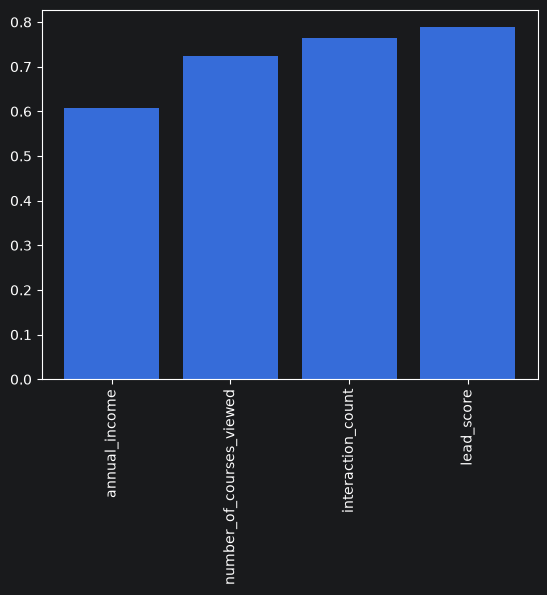

In [53]:
import matplotlib.pyplot as plt

plt.bar(numerical_columns, scores)
plt.xticks(rotation=90)
plt.show()

In [54]:
for i, col in enumerate(numerical_columns):
    score = scores[i]
    print(f"{col}: {score}")

annual_income: 0.6081977776250831
number_of_courses_viewed: 0.7229894623989618
interaction_count: 0.7649203047563227
lead_score: 0.7882254810906102


In [55]:
def prepare_split(df_split, target='converted'):
    df_split = df_split.reset_index(drop=True)
    y = df_split[target].values
    X = df_split.drop(columns=[target])
    return X, y

df_full_train = df_full_train.reset_index(drop=True)
df_train, y_train = prepare_split(df_train)
df_val, y_val = prepare_split(df_val)
df_test, y_test = prepare_split(df_test)

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [78]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_columns + numerical_columns].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return model, dv

In [77]:
def predict(model, dv, df):
    dicts = df[categorical_columns + numerical_columns].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [61]:
model, dv = train(df_train, y_train)
y_pred = predict(model, dv, df_val)

In [64]:
auc = roc_auc_score(y_val, y_pred)
print(auc)

0.7318222288173319


In [66]:
import numpy as np
from sklearn.metrics import precision_score, recall_score
scores = []

for t in np.linspace(0.0, 1.0, 101):
    p = precision_score(y_val, y_pred >= t, zero_division=0)
    r = recall_score(y_val, y_pred >= t, zero_division=0)
    scores.append((t, p, r))

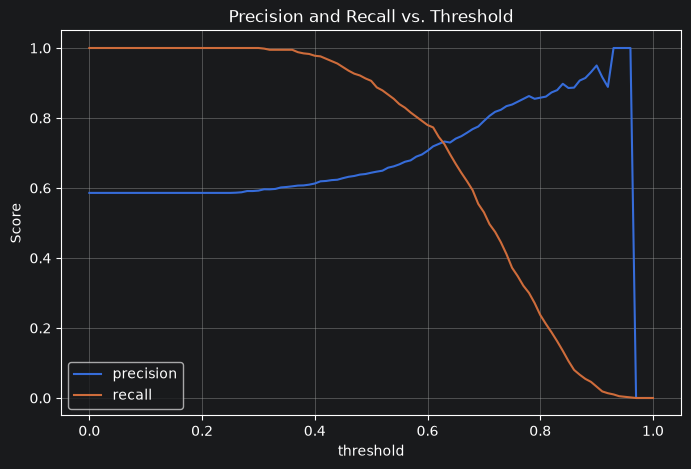

In [70]:
df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

df_scores.plot(x='threshold', y=['precision', 'recall'], figsize=(8, 5), grid=True)
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.show()

In [74]:
from sklearn.metrics import f1_score
f1_scores = []

for t in np.linspace(0.0, 1.0, 101):
    f1 = f1_score(y_val, y_pred >= t, zero_division=0)
    f1_scores.append((t, f1))

df_f1 = pd.DataFrame(f1_scores, columns=['threshold', 'f1'])

# Find the threshold with the highest F1 score
best_row = df_f1.loc[df_f1['f1'].idxmax()]

print(f"Best Threshold: {best_row['threshold']:.2f}")
print(f"Max F1 Score:   {best_row['f1']:.4f}")

Best Threshold: 0.41
Max F1 Score:   0.7576


In [81]:
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = y_full_train[train_idx]
        y_va = y_full_train[val_idx]

        # 1. Unpack matching: return model, dv
        model, dv = train(df_tr, y_tr, C=C)

        # 2. Call matching: predict(model, dv, df)
        y_pred = predict(model, dv, df_va)

        auc = roc_auc_score(y_va, y_pred)
        scores.append(auc)

    print(f"C={C:<8} | Mean AUC: {np.mean(scores):.4f} +- {np.std(scores):.4f}")


C=1e-06    | Mean AUC: 0.6167 +- 0.0187
C=0.001    | Mean AUC: 0.7492 +- 0.0100
C=1        | Mean AUC: 0.7317 +- 0.0069
